<p style="color: purple;">
<b>Étudiants :</b> Annie KADIAMBU, Ilyas KABCHI<br>
<b>Classe :</b> TD C<br>
<b>Module :</b> Algorithme d'apprentissage A3
</p>

# Prédiction de prix de airbnb

But : Prédire le logarithme du prix du airbnb à partir d'un ensemble d'informations brut sur le logement

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


In [2]:
# Chargement du fichier csv
df = pd.read_csv("airbnb_train.csv")
df.head()

,id,log_price,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,...,last_review,latitude,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,zipcode,bedrooms,beds
0,5708593,4.317488,House,Private room,"{TV,""Wireless Internet"",Kitchen,""Free parking ...",3,1.0,Real Bed,flexible,False,...,NaN,33.782712,-118.134410,Island style Spa Studio,Long Beach,0,NaN,90804,0.0,2.0
1,14483613,4.007333,House,Private room,"{""Wireless Internet"",""Air conditioning"",Kitche...",4,2.0,Real Bed,strict,False,...,2017-09-17,40.705468,-73.909439,"Beautiful and Simple Room W/2 Beds, 25 Mins to...",Ridgewood,38,86.0,11385,1.0,2.0
2,10412649,7.090077,Apartment,Entire home/apt,"{TV,""Wireless Internet"",""Air conditioning"",Kit...",6,2.0,Real Bed,flexible,False,...,NaN,38.917537,-77.031651,2br/2ba luxury condo perfect for infant / toddler,U Street Corridor,0,NaN,20009,2.0,2.0
3,17954362,3.555348,House,Private room,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",1,1.0,Real Bed,flexible,True,...,2017-09-29,40.736001,-73.924248,Manhattan view from Queens. Lovely single room .,Sunnyside,19,96.0,11104,1.0,1.0
4,9969781,5.480639,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.0,Real Bed,moderate,True,...,2017-08-28,37.744896,-122.430665,Zen Captured Noe Valley House,Noe Valley,15,96.0,94131,2.0,2.0


# Section 1 : Présentation des données

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22234 entries, 0 to 22233
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      22234 non-null  int64  
 1   log_price               22234 non-null  float64
 2   property_type           22234 non-null  object 
 3   room_type               22234 non-null  object 
 4   amenities               22234 non-null  object 
 5   accommodates            22234 non-null  int64  
 6   bathrooms               22183 non-null  float64
 7   bed_type                22234 non-null  object 
 8   cancellation_policy     22234 non-null  object 
 9   cleaning_fee            22234 non-null  bool   
 10  city                    22234 non-null  object 
 11  description             22234 non-null  object 
 12  first_review            17509 non-null  object 
 13  host_has_profile_pic    22178 non-null  object 
 14  host_identity_verified  22178 non-null

On voit que de nombreuses données ne sont pas au format numériques et donc difficilement exploitables en l'état avec les algos que l'on utilise.

In [4]:
df.columns

Index(['id', 'log_price', 'property_type', 'room_type', 'amenities',
       'accommodates', 'bathrooms', 'bed_type', 'cancellation_policy',
       'cleaning_fee', 'city', 'description', 'first_review',
       'host_has_profile_pic', 'host_identity_verified', 'host_response_rate',
       'host_since', 'instant_bookable', 'last_review', 'latitude',
       'longitude', 'name', 'neighbourhood', 'number_of_reviews',
       'review_scores_rating', 'zipcode', 'bedrooms', 'beds'],
      dtype='object')

In [5]:
print("\n=== Statistiques pour colonnes numériques ===")
df.describe()


=== Statistiques pour colonnes numériques ===


,id,log_price,accommodates,bathrooms,latitude,longitude,number_of_reviews,review_scores_rating,bedrooms,beds
count,2.223400e+04,22234.000000,22234.000000,22183.000000,22234.000000,22234.000000,22234.000000,17256.000000,22208.000000,22199.000000
mean,1.122269e+07,4.783481,3.155573,1.236037,38.462971,-92.269305,20.670774,94.069077,1.264769,1.711473
std,6.080480e+06,0.718758,2.143870,0.586246,3.071679,21.670081,37.183731,7.782235,0.852819,1.254903
min,3.362000e+03,2.302585,1.000000,0.000000,33.339002,-122.510940,0.000000,20.000000,0.000000,0.000000
25%,6.202924e+06,4.317488,2.000000,1.000000,34.136082,-118.340633,1.000000,92.000000,1.000000,1.000000
50%,1.217425e+07,4.700480,2.000000,1.000000,40.662632,-76.994944,6.000000,96.000000,1.000000,1.000000
75%,1.639502e+07,5.220356,4.000000,1.000000,40.746358,-73.954599,23.000000,100.000000,1.000000,2.000000
max,2.120450e+07,7.600402,16.000000,8.000000,42.390248,-70.989359,505.000000,100.000000,10.000000,18.000000


Les variables numériques sont sur des échelles très différentes (ex: `latitude` ~40, `bedrooms` ~1, `number_of_reviews` jusqu'à 505). Une standardisation sera appliquée avant les modèles sensibles aux échelles (régression linéaire, ACP).

In [6]:
print("\n=== Nombre de valeurs nulles ===")
df.isnull().sum()


=== Nombre de valeurs nulles ===


id                           0
log_price                    0
property_type                0
room_type                    0
amenities                    0
accommodates                 0
bathrooms                   51
bed_type                     0
cancellation_policy          0
cleaning_fee                 0
city                         0
description                  0
first_review              4725
host_has_profile_pic        56
host_identity_verified      56
host_response_rate        5475
host_since                  56
instant_bookable             0
last_review               4716
latitude                     0
longitude                    0
name                         0
neighbourhood             2086
number_of_reviews            0
review_scores_rating      4978
zipcode                    303
bedrooms                    26
beds                        35
dtype: int64

Certaines variables ont des valeurs manquantes :
- `bathrooms`, `bedrooms`, `beds` (<1%) → remplacement par la médiane
- `host_response_rate`, `review_scores_rating` (~22-25%) → remplacement par la médiane
- `first_review`, `last_review` (~21%) → les nulls signifient "jamais de review", 
  traités lors du feature engineering
- `neighbourhood` (9% + trop de valeurs uniques) → supprimée

# Section 2 : Distribution de la variable cible (log_price)

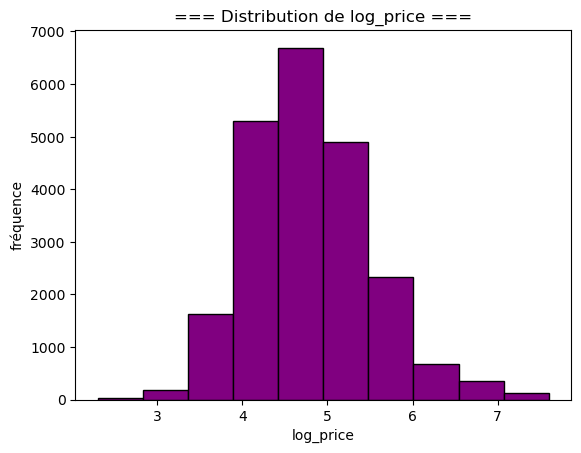

In [7]:
plt.title("=== Distribution de log_price ===")
plt.hist(df["log_price"],bins=10,color="purple",edgecolor="black")
plt.xlabel("log_price")
plt.ylabel("fréquence")
plt.show()

# Section 3 : Exploration des variables catégorielles et numériques

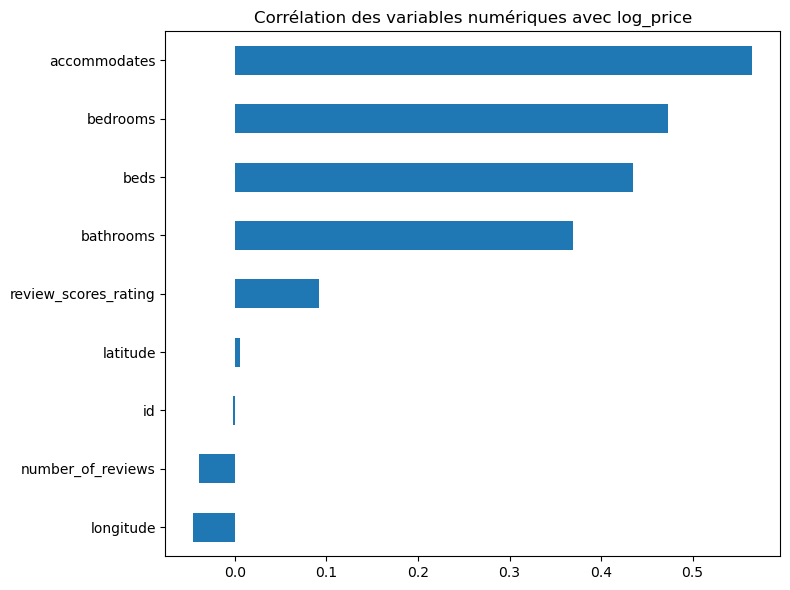

In [8]:
# Sélectionner uniquement les colonnes numériques
numeric_cols = df.select_dtypes(include=['number']).columns

corr = df[numeric_cols].corr()['log_price'].drop('log_price').sort_values()
corr.plot(kind='barh', figsize=(8, 6))
plt.title('Corrélation des variables numériques avec log_price')
plt.tight_layout()
plt.show()

## Observations
- Les variables de capacité (`accommodates`, `bedrooms`, `beds`, `bathrooms`) sont 
  fortement corrélées avec `log_price` : plus le logement est grand, plus il est cher.
- `latitude`/`longitude` ont une corrélation linéaire quasi nulle, mais on les conserve
  car des modèles non-linéaires (Random Forest) peuvent détecter des effets de zone.
- `id` est un identifiant sans valeur prédictive : on le supprime.

## L'idée
`accommodates`, `bedrooms`, `beds`, `bathrooms` sont toutes fortement corrélées entre elles et avec `log_price`. Un grand appartement a tendance à avoir beaucoup de chambres, beaucoup de lits, beaucoup de salles de bain... Ces 4 colonnes portent en grande partie la même information : "la taille du logement".
L'ACP va justement détecter ça et créer une nouvelle colonne, qu'on appellera composante principale, résumant ces 4 variables en 1 seule, tout en gardant le maximum d'information.

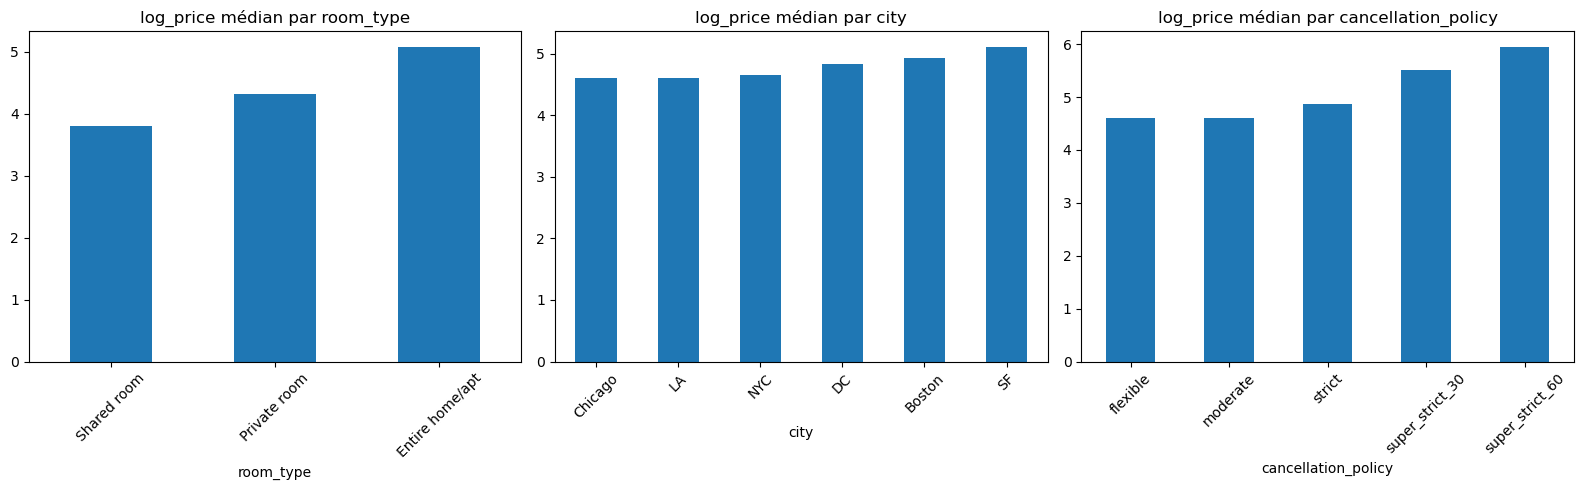

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ['room_type', 'city', 'cancellation_policy']):
    df.groupby(col)['log_price'].median().sort_values().plot(kind='bar', ax=ax)
    ax.set_title(f'log_price médian par {col}')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

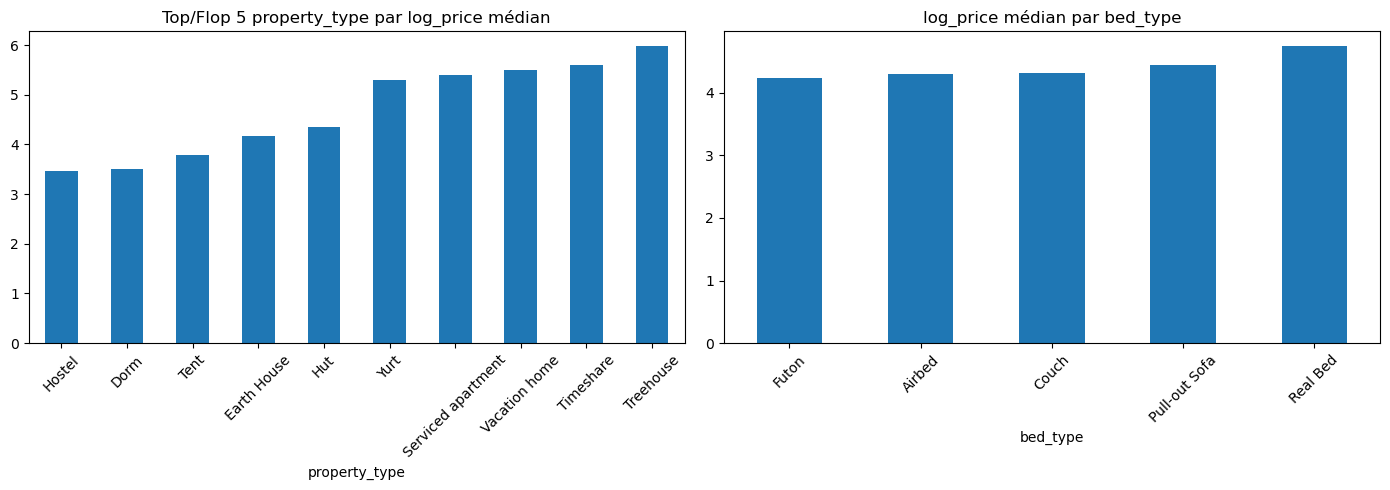

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# property_type : 5 premiers et 5 derniers uniquement car sinon c'est illisible
medians = df.groupby('property_type')['log_price'].median().sort_values()
pd.concat([medians.head(5), medians.tail(5)]).plot(kind='bar', ax=axes[0])
axes[0].set_title('Top/Flop 5 property_type par log_price médian')
axes[0].tick_params(axis='x', rotation=45)

# bed_type : tous 
df.groupby('bed_type')['log_price'].median().sort_values().plot(kind='bar', ax=axes[1])
axes[1].set_title('log_price médian par bed_type')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Observations

``property_type`` : Grande disparité de prix selon le type de bien. 
Les hébergements insolites (``Treehouse``, ``Timeshare``) sont les plus chers, 
tandis que les hébergements collectifs (``Hostel``, ``Dorm``) sont les moins chers. 
Cette variable sera donc à conservée par la suite.

``bed_type``: Faible disparité des prix (de 4.2 à 5.8). 
``Real Bed`` est légèrement plus cher. Variable conservée mais probablement peu influente.

## Conclusion de l'exploration

- Variables à encoder (texte → nombres) : ``room_type``, ``city``, 
``cancellation_policy``, ``property_type``, ``bed_type``

- Variables à transformer : ``amenities``, ``host_since``, ``first_review``, 
``last_review``, ``host_response_rate``, ``cleaning_fee``, ``host_has_profile_pic``,
``host_identity_verified``, ``instant_bookable``

- Variables à supprimer : ``id``, ``description``, ``name``, ``zipcode``, ``neighbourhood``



# Section 4 : Feature engineering

In [11]:
# Suppresion des colonnes inutiles 
df = df.drop(columns=['id', 'description', 'name', 'zipcode', 'neighbourhood'])
df.shape

(22234, 23)

In [12]:
# Remplissage des valeurs manquantes
# Numériques ==> médiane
for col in ['bathrooms', 'bedrooms', 'beds', 'review_scores_rating']:
    df[col] = df[col].fillna(df[col].median())

# host_response_rate : enlever le % puis médiane
df['host_response_rate'] = df['host_response_rate'].str.replace('%', '').astype(float)
df['host_response_rate'] = df['host_response_rate'].fillna(df['host_response_rate'].median())



In [13]:
# Conversion des valeurs booléennes informelles
for col in ['host_has_profile_pic', 'host_identity_verified', 'instant_bookable']:
    df[col] = df[col].map({'t': 1, 'f': 0, True: 1, False: 0})

df.iloc[0:6,11:18]


,host_has_profile_pic,host_identity_verified,host_response_rate,host_since,instant_bookable,last_review,latitude
0,1.0,0.0,100.0,2015-12-12,1,NaN,33.782712
1,1.0,1.0,100.0,2016-11-04,1,2017-09-17,40.705468
2,1.0,0.0,100.0,2016-12-11,1,NaN,38.917537
3,1.0,1.0,100.0,2012-08-04,0,2017-09-29,40.736001
4,1.0,1.0,100.0,2013-07-25,0,2017-08-28,37.744896
5,1.0,1.0,100.0,2012-11-19,0,NaN,40.738580


In [14]:
# Transformation des dates au format numériques
df['last_review'] = pd.to_datetime(df['last_review'], errors='coerce')
ref = df['last_review'].max() + pd.Timedelta(days=1) # date la plus récente du dataset + 1 jour

for col in ['host_since', 'first_review', 'last_review']:
    df[col] = pd.to_datetime(df[col], errors='coerce')
    df[col] = (ref - df[col]).dt.days.fillna(0) # nombre de jour d'activité

df[['host_since', 'first_review', 'last_review']].head()

,host_since,first_review,last_review
0,664.0,0.0,0.0
1,336.0,152.0,19.0
2,299.0,0.0,0.0
3,1889.0,364.0,7.0
4,1534.0,376.0,39.0


In [15]:
# Quels sont les équipements les plus fréquents ?
from collections import Counter

all_amenities = df['amenities'].str.strip('{}').str.replace('"', '').str.split(',')
counter = Counter([a.strip() for sublist in all_amenities for a in sublist])

#pd.Series(counter).info()
pd.Series(counter).sort_values(ascending=False).to_csv("Amenities.csv")

## Observation
Parmi les équipements les plus fréquents, certains sont liés à la législation (détecteur de fumée, extincteur...) et non au confort ou au standing du logement. On les exclut manuellement car ils ne sont pas significativement impactant sur le prix.
On retient les équipements de confort les plus fréquent en excluant : 
- Sécurité/législation : ``Smoke detector``, ``Carbon monoxide detector``, ``Fire extinguisher``, ``First aid kit`` (obligatoires dans beaucoup d'états)
- Accessibilité : ``Wide doorway``, ``Wheelchair accessible``, etc. (non liés au prix)
- Trop rares (<100 occurrences) : ``Beachfront``, ``Ski in/Ski out``, etc.
- Ambigus : "translation missing", "Other"

In [16]:
# Extraction des données dans amenities (= infrastructures)

amenities_to_extract = {
    'has_tv': 'TV',
    'has_wifi': 'Wireless Internet',
    'has_kitchen': 'Kitchen',
    'has_free_parking': 'Free parking on premises',
    'has_washer': 'Washer',
    'has_dryer': 'Dryer',
    'has_ac': 'Air conditioning',
    'has_heating': 'Heating',
    'has_family_friendly': 'Family/kid friendly',
    'has_laptop_workspace': 'Laptop friendly workspace',
    'has_cable_tv': 'Cable TV',
    'has_internet': 'Internet',
    'has_breakfast': 'Breakfast',
    'has_gym': 'Gym',
    'has_hot_tub': 'Hot tub',
    'has_pool': 'Pool',
    'has_pets_allowed': 'Pets allowed',
    'has_24h_checkin': '24-hour check-in',
    'has_self_checkin': 'Self Check-In',
}

for col_name, amenity in amenities_to_extract.items():
    df[col_name] = df['amenities'].str.contains(amenity, case=False).astype(int)

df['nb_amenities'] = df['amenities'].str.count(',') + 1
df = df.drop(columns=['amenities'])
df.head()

,log_price,property_type,room_type,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,first_review,...,has_cable_tv,has_internet,has_breakfast,has_gym,has_hot_tub,has_pool,has_pets_allowed,has_24h_checkin,has_self_checkin,nb_amenities
0,4.317488,House,Private room,3,1.0,Real Bed,flexible,False,LA,0.0,...,0,1,0,0,0,0,1,0,0,15
1,4.007333,House,Private room,4,2.0,Real Bed,strict,False,NYC,152.0,...,0,1,0,0,0,0,0,1,1,25
2,7.090077,Apartment,Entire home/apt,6,2.0,Real Bed,flexible,False,DC,0.0,...,0,1,0,0,0,0,1,0,0,20
3,3.555348,House,Private room,1,1.0,Real Bed,flexible,True,NYC,364.0,...,1,1,1,0,0,0,0,0,1,30
4,5.480639,House,Entire home/apt,4,1.0,Real Bed,moderate,True,SF,376.0,...,1,1,1,0,0,0,0,1,1,24


In [17]:
# encoder les variables catégorielles
df = pd.get_dummies(df, columns=['room_type', 'property_type', 'bed_type', 'city', 'cancellation_policy'])
print(df.shape)
df.head()

(22234, 87)


,log_price,accommodates,bathrooms,cleaning_fee,first_review,host_has_profile_pic,host_identity_verified,host_response_rate,host_since,instant_bookable,...,city_Chicago,city_DC,city_LA,city_NYC,city_SF,cancellation_policy_flexible,cancellation_policy_moderate,cancellation_policy_strict,cancellation_policy_super_strict_30,cancellation_policy_super_strict_60
0,4.317488,3,1.0,False,0.0,1.0,0.0,100.0,664.0,1,...,False,False,True,False,False,True,False,False,False,False
1,4.007333,4,2.0,False,152.0,1.0,1.0,100.0,336.0,1,...,False,False,False,True,False,False,False,True,False,False
2,7.090077,6,2.0,False,0.0,1.0,0.0,100.0,299.0,1,...,False,True,False,False,False,True,False,False,False,False
3,3.555348,1,1.0,True,364.0,1.0,1.0,100.0,1889.0,0,...,False,False,False,True,False,True,False,False,False,False
4,5.480639,4,1.0,True,376.0,1.0,1.0,100.0,1534.0,0,...,False,False,False,False,True,False,True,False,False,False


On va remettre tout le processing dans une fonction pour pouvoir l'appliquer sur le fichier de test également.

In [18]:
def preprocess(df, ref_date=None):
    df = df.copy()
    
    # Suppression des colonnes inutiles
    df = df.drop(columns=['description', 'name', 'zipcode', 'neighbourhood'], errors='ignore')
    
    # Valeurs manquantes numériques
    for col in ['bathrooms', 'bedrooms', 'beds', 'review_scores_rating']:
        df[col] = df[col].fillna(df[col].median())
    
    # host_response_rate
    if df['host_response_rate'].dtype == object:
        df['host_response_rate'] = df['host_response_rate'].str.replace('%', '').astype(float)
        df['host_response_rate'] = df['host_response_rate'].fillna(df['host_response_rate'].median())
    
    # Booléens
    for col in ['host_has_profile_pic', 'host_identity_verified', 'instant_bookable']:
        df[col] = df[col].map({'t': 1, 'f': 0, True: 1, False: 0})
        df[col] = df[col].fillna(df[col].median())
    
    # Dates
    if ref_date is None:
        ref_date = pd.to_datetime(df['last_review'], errors='coerce').max() + pd.Timedelta(days=1)
    for col in ['host_since', 'first_review', 'last_review']:
        df[col] = pd.to_datetime(df[col], errors='coerce')
        df[col] = (ref_date - df[col]).dt.days.fillna(0)
    
    # Infrastructures
    amenities_to_extract = {
        'has_tv': 'TV', 'has_wifi': 'Wireless Internet',
        'has_kitchen': 'Kitchen', 'has_free_parking': 'Free parking on premises',
        'has_washer': 'Washer', 'has_dryer': 'Dryer',
        'has_ac': 'Air conditioning', 'has_heating': 'Heating',
        'has_family_friendly': 'Family/kid friendly',
        'has_laptop_workspace': 'Laptop friendly workspace',
        'has_cable_tv': 'Cable TV', 'has_internet': 'Internet',
        'has_breakfast': 'Breakfast', 'has_gym': 'Gym',
        'has_elevator': 'Elevator', 'has_hot_tub': 'Hot tub',
        'has_pool': 'Pool', 'has_indoor_fireplace': 'Indoor fireplace',
        'has_pets_allowed': 'Pets allowed', 'has_24h_checkin': '24-hour check-in',
        'has_self_checkin': 'Self Check-In', 'has_private_entrance': 'Private entrance',
    }
    for col_name, amenity in amenities_to_extract.items():
        df[col_name] = df['amenities'].str.contains(amenity, case=False).astype(int)
    df['nb_amenities'] = df['amenities'].str.count(',') + 1
    df = df.drop(columns=['amenities'])
    
    # Encodage catégorielles
    df = pd.get_dummies(df, columns=['room_type', 'property_type', 'bed_type', 'city', 'cancellation_policy'])
    return df, ref_date

In [19]:
df_test = pd.read_csv("airbnb_test.csv")
df_train = pd.read_csv("airbnb_train.csv")
df_train, ref_date = preprocess(df_train)
df_test, _ = preprocess(df_test, ref_date=ref_date)

In [20]:
# Aligner les colonnes du test sur le train
# Le test n'a pas log_price, donc on l'exclut de la référence
train_cols = [c for c in df_train.columns if c != 'log_price']
df_test = df_test.reindex(columns=train_cols, fill_value=0)

print(df_test.shape)
print(df_train.shape)

(51877, 90)
(22234, 91)


# Section 5 : Modélisation

On commence par séparer les données d'entraînement.

In [21]:
X_train = df_train.drop(columns=['log_price'])
y_train = df_train['log_price']

## Modèle naïf
Avant de tester des modèles complexes, on définit un modèle naïf qui prédit toujours la moyenne de log_price. Tout modèle réel devra faire mieux que ce score pour être utile.

On évalue avec une **validation croisée à 5 folds** (cross-validation) plutôt 
qu'un simple train/test split, pour avoir une estimation plus fiable des performances.

La métrique utilisée est le **RMSE** (Root Mean Squared Error) : 
l'erreur moyenne entre la prédiction et la vraie valeur. 
(==> plus c'est bas, mieux c'est)


In [22]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score
import numpy as np

model = DummyRegressor(strategy='mean')
scores = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
print(f"Baseline RMSE : {-scores.mean():.4f}")

Baseline RMSE : 0.7187


## Modèle régression linéaire Ridge

On cherche une formule du type :
log_price = a × accommodates + b × bedrooms + c × has_wifi + ...,
avec les meilleurs coefs possibles (a,b,c,...).

Par rapport à une régression linéaire classique, Ridge ajoute une pénalité qui empêche les coefficients de devenir trop grands. Cela évite que le modèle "mémorise" les données d'entraînement sans vraiment apprendre les tendances générales ==> éviter le surapprentissage.

On cumule 2 étapes :
- **Standardisation des données (car Ridge est sensible aux écarts d'échelle entre les variables)**
- **Application du modèle Ridge**



In [23]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

ridge_pipe = Pipeline([('scaler', StandardScaler()),('model', Ridge())])

scores = cross_val_score(ridge_pipe, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
print(f"Ridge RMSE : {-scores.mean():.4f}")

Ridge RMSE : 0.4631


RMSE = 0.4631 < 0.7187 ==> **le modèle apporte une amélioration significative**

## Modèle Random Forest

Une forêt aléatoire est un ensemble de nombreux arbres de décision entraînés chacun sur une portion aléatoire des données.

Un arbre de décision fonctionne comme une série de questions :
- "Est-ce que accommodates > 4 ?"
  - Oui → "Est-ce que la ville est SF ?"
    - Oui → log_price prédit = 5.2
    - Non → log_price prédit = 4.8
  - Non → ...

Le problème d'un seul arbre c'est qu'il a tendance à trop coller aux données d'entraînement (surapprentissage). La forêt aléatoire résout ça en construisant 100 arbres différents et en faisant la moyenne de leurs prédictions. Les erreurs de chaque arbre se compensent mutuellement.

Contrairement à Ridge, ce modèle n'est pas sensible aux écarts d'échelle entre les variables, donc pas besoin de standardisation.

In [24]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
scores = cross_val_score(rf, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
print(f"Random Forest RMSE : {-scores.mean():.4f}")

Random Forest RMSE : 0.4077


RMSE = 0.4077 < 0.4631 pour Ridge ==> **random forest fait mieux car elle capture des relations non-linéaires 
entre les variables et le prix, ce que Ridge ne peut pas faire**

## Modèle Gradient Boosting

Le Gradient Boosting est aussi un ensemble d'arbres de décision, mais 
avec une stratégie différente de la forêt aléatoire.

La forêt aléatoire construit tous ses arbres indépendamment tandis que le Gradient Boosting les construit en séquence : chaque nouvel arbre corrige les erreurs du précédent. 
En contrepartie, ce modèle est plus long à entraîner et plus sensible au surapprentissage.


In [25]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(n_estimators=100, random_state=42)
scores = cross_val_score(gb, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
print(f"Gradient Boosting RMSE : {-scores.mean():.4f}")

Gradient Boosting RMSE : 0.4118



RMSE = 0.4118 > 0.4077 pour la random forest ==> **les 2 modèles sont très proches mais la RF reste légèrement meilleure**

# Application de l'ACP

L'ACP (Analyse en Composantes Principales) est une technique de réduction de dimensions. Elle résume les 90 colonnes en un nombre réduit de nouvelles variables qui concentrent l'essentiel de l'information en minimisant la perte de données.

On teste différents nombres de composantes à conserver et on observe l'impact sur le RMSE.


## ACP + Ridge
Le graphe montre que plus on conserve de composantes, plus le score 
s'améliore, mais sans jamais dépasser Ridge seul (ligne rouge).

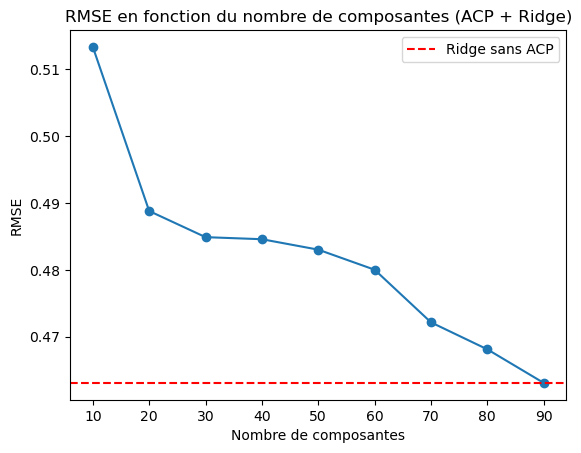

In [26]:
from sklearn.decomposition import PCA

composantes = [10, 20, 30, 40, 50, 60, 70, 80, 90]
rmses = []

for n in composantes:
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('acp', PCA(n_components=n)),
        ('model', Ridge())
    ])
    scores = cross_val_score(pipe, X_train, y_train,
                             cv=5, scoring='neg_root_mean_squared_error')
    rmses.append(-scores.mean())

plt.plot(composantes, rmses, marker='o')
plt.xlabel('Nombre de composantes')
plt.ylabel('RMSE')
plt.title('RMSE en fonction du nombre de composantes (ACP + Ridge)')
plt.axhline(y=0.4631, color='r', linestyle='--', label='Ridge sans ACP')
plt.legend()
plt.show()

**Conclusion :**
L'ACP ne permet pas d'améliorer les prédictions ici. En revanche, elle offre un compromis intéressant : avec seulement 40 
composantes au lieu de 90 (soit moitié moins de données à traiter), on obtient un RMSE de 0.485, légèrement moins bon, mais avec un modèle 2 fois plus léger. 

## ACP sur chaque modèle (40 composantes)

In [28]:
from sklearn.decomposition import PCA
import plotly.express as px

resultats = {}

# Ridge sans/avec ACP
pipe = Pipeline([('scaler', StandardScaler()), ('model', Ridge())])
scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
resultats['Ridge sans ACP'] = -scores.mean()

pipe = Pipeline([('scaler', StandardScaler()), ('acp', PCA(n_components=40)), ('model', Ridge())])
scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
resultats['Ridge avec ACP'] = -scores.mean()

# Forêt aléatoire sans/avec ACP
rf = RandomForestRegressor(n_estimators=100, random_state=42)
scores = cross_val_score(rf, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
resultats['Forêt aléatoire sans ACP'] = -scores.mean()

pipe = Pipeline([('scaler', StandardScaler()), ('acp', PCA(n_components=40)), ('model', RandomForestRegressor(n_estimators=100, random_state=42))])
scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
resultats['Forêt aléatoire avec ACP'] = -scores.mean()

# Gradient Boosting sans/avec ACP
gb = GradientBoostingRegressor(n_estimators=100, random_state=42)
scores = cross_val_score(gb, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
resultats['Gradient Boosting sans ACP'] = -scores.mean()

pipe = Pipeline([('scaler', StandardScaler()), ('acp', PCA(n_components=40)), ('model', GradientBoostingRegressor(n_estimators=100, random_state=42))])
scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
resultats['Gradient Boosting avec ACP'] = -scores.mean()



In [29]:
# Affichage sous forme de graphe
noms = list(resultats.keys())
rmses = list(resultats.values())

df_resultats = pd.DataFrame({
    'Modèle': list(resultats.keys()),
    'RMSE': list(resultats.values()),
    'Type': ['sans ACP' if 'sans' in n else 'avec ACP' for n in resultats.keys()]
})

fig = px.bar(df_resultats, 
             x='RMSE', 
             y='Modèle', 
             color='Type',
             title='Comparaison des modèles avec et sans ACP',
             orientation='h',
             hover_data={'RMSE': ':.4f'})

fig.add_vline(x=0.7187, line_dash='dash', line_color='black', 
              annotation_text='Baseline')

fig.show()

## Analyse comparative et choix du modèle final

Le graphe montre 2 résultats importants :

**1. L'ACP dégrade significativement les performances des modèles à base d'arbres (Random Forest, Gradient Boosting). Ces modèles exploitent les variables originales directement, en les résumant en composantes, on leur fait perdre de l'information utile.**

**2. Sans ACP, la forêt aléatoire obtient le meilleur score (RMSE = 0.4077).**

**Modèle retenu : Forêt aléatoire sans ACP.**

Remarque : Ridge avec ACP (RMSE ≈ 0.46) reste intéressant si les ressources de calcul sont limitées, car il traite 2 fois moins de variables pour un résultat acceptable/similaire. Dans notre cas, on privilégie la précision pour un projet scolaire avec une quantité de données limitées.

# Section 6 : Prédiction final


On entraîne la forêt aléatoire sur l'intégralité des données 
d'entraînement (22 234 logements) et on prédit le log_price 
pour les 51 877 logements du fichier test.

Les prédictions sont exportées dans un fichier predictions.csv 
au format attendu : une colonne id et une colonne log_price.

In [33]:
# Entraînement sur toutes les données
best_model = RandomForestRegressor(n_estimators=100, random_state=42)
best_model.fit(X_train, y_train)

# Prédiction sur le fichier test
df_test_original = pd.read_csv("airbnb_test.csv")
predictions = best_model.predict(df_test)

# Export des réponses
submission = pd.DataFrame({
    'id': df_test_original['Unnamed: 0'],
    'logpred': predictions
})

submission.to_csv("predictions.csv", index=False)
print(submission.head())
print(f"Nombre de prédictions : {len(submission)}")

         id   logpred
0  14282777  4.944870
1  17029381  5.932765
2   7824740  4.880821
3  19811650  5.857093
4  12410741  4.950951
Nombre de prédictions : 51877


# Section 7 : Conclusion générale

| Modèle | RMSE |
|---|---|
| Baseline | 0.7187 |
| Ridge | 0.4631 |
| Gradient Boosting | 0.4118 |
| Forêt aléatoire | 0.4077 |

Le modèle retenu est le Random Forest sans ACP, qui obtient le meilleur RMSE. L'ACP a été testée sur les 3 modèles mais dégrade systématiquement les performances des modèles à base d'arbres, qui exploitent mieux les variables originales.

La principale source d'amélioration par rapport à la baseline vient du feature engineering : transformation des amenities, 
encodage des variables catégorielles, et conversion des dates en ancienneté en jours.